# Studiul de caz 2 - Watt's next? Prognoza consumului național al României pentru ziua următoare

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Proșcanu, C. A., Proșcanu, M. E., Pele, D. T. și Costea, A. (2025). Watt's next? Benchmarking time series models on Romania's
national electricity consumption. *Romanian Journal of Economic Forecasting*, 28(3), 146-163.

**Conținutul notebook-ului.** Variabila prognozată și eșantionul sînt aceleași ca în lucrare: consumul național orar, 1 ianuarie 2022 – 31 decembrie 2024 (26.304 ore),
împărțit cronologic în proporția 80/20, cu prognoze pentru următoarele 24 de ore. Comparăm șase modele din patru categorii: repere naive sezoniere,
modele statistice (SARIMA, model autoregresiv integrat cu medie mobilă și componentă sezonieră; o regresie liniară cu variabile calendaristice și valori decalate), modele de învățare automată
(gradient boosting; o rețea neuronală care transformă ultimele 168 de ore în prognoza pentru următoarele 24, după principiul N-BEATS) și un model fundamental preantrenat,
folosit fără reantrenare (*zero-shot*): Chronos-Bolt.

**Adaptarea pentru curs.** Datele de consum provin de la ENTSO-E, prin energy-charts.info (lucrarea a folosit sistemulenergetic.ro / Transelectrica);
prognozăm ziua d la închiderea porții (ora 12:00 CET în ziua d-1), folosind consumul măsurat pînă la sfîrșitul zilei d-2 (ziua d-1 nu este încă măsurată); rețeaua neuronală este un perceptron multistrat compact, iar pentru Chronos folosim
versiunea redusă „Bolt”, ambele alese astfel încît notebook-ul să poată rula la curs.

## 1. Datele: este aceeași serie ca în lucrare?

In [2]:
g = cu.generation_ro_hourly()
load = g["load"].loc["2022-01-01":"2024-12-31"].astype(float)          # MW = MWh per hour
print(len(load), "hours, missing:", load.isna().sum())
desc = load.describe()
paper = pd.Series({"count": 26304, "mean": 6230.59, "std": 980.25, "min": 2871.75, "50%": 6178.75, "max": 9210.75})
print(pd.DataFrame({"our data": desc[paper.index], "paper Table 1": paper}).round(2))

26304 hours, missing: 0
       our data  paper Table 1
count  26304.00       26304.00
mean    6230.90        6230.59
std      979.87         980.25
min     2871.75        2871.75
50%     6178.75        6178.75
max     9210.75        9210.75


Seria noastră reproduce aproape la zecimală statisticile descriptive din lucrare (Tabelul 1, p. 149): ambele provin din aceleași măsurători
ale Transelectrica, publicate o dată de OTS și o dată de ENTSO-E.

test starts 2024-05-27 | test hours 5256 | fitting data end before 2024-05-26 00:00:00+02:00


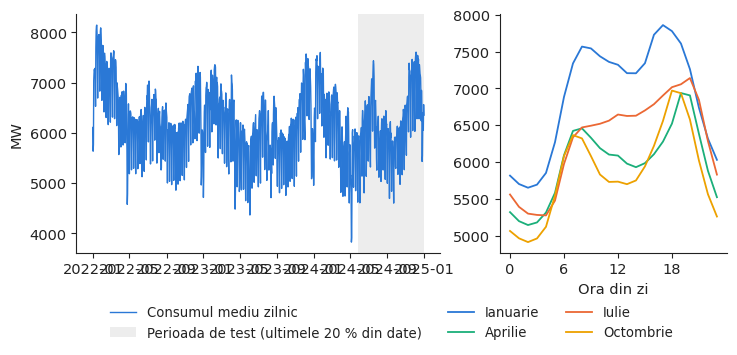

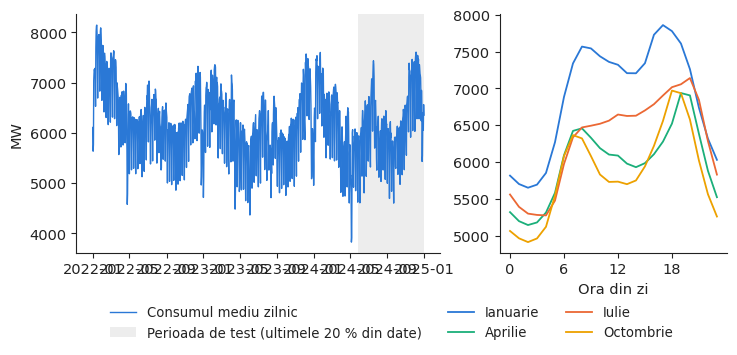

In [3]:
load = load.tz_convert("Europe/Brussels")       # from here on: CET/CEST delivery days, as in the day-ahead market
TZ = load.index.tz
cal_day = lambda ts, k: (ts.tz_localize(None).normalize() + pd.Timedelta(days=k)).tz_localize(TZ)   # midnight of the CALENDAR day ts + k
daily = load.resample("D").mean()
n = len(load); split = cal_day(load.index[int(0.8 * n)], 1)          # first full test day (CET)
fit_end = cal_day(split, -1)                    # models are fitted once, before the first forecast: data up to the end of split-2 only
print("test starts", split.date(), "| test hours", (load.index >= split).sum(), "| fitting data end before", fit_end)
def fig_series(lang):
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.1), gridspec_kw={"width_ratios": [1.6, 1]})
    a = axes[0]
    a.plot(daily.index, daily.values, color=cu.PAL["RO"], lw=1.0, label=cu.T(lang, "Daily mean load", "Consumul mediu zilnic"))
    a.axvspan(split, daily.index.max(), color=cu.MUTED, alpha=0.15, lw=0, label=cu.T(lang, "Test period (last 20 %)", "Perioada de test (ultimele 20 % din date)"))
    a.set_ylabel("MW")
    b = axes[1]
    prof = load.groupby([load.index.month, load.index.hour]).mean().unstack(0)
    for m, col, lab in [(1, cu.PAL["RO"], ("January", "Ianuarie")), (4, cu.PAL["HU"], ("April", "Aprilie")),
                        (7, cu.PAL["DE_LU"], ("July", "Iulie")), (10, cu.PAL["BG"], ("October", "Octombrie"))]:
        b.plot(prof.index, prof[m], color=col, label=cu.T(lang, *lab))
    b.set_xlabel(cu.T(lang, "Hour of day", "Ora din zi")); b.set_xticks(range(0, 24, 6))
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_series, "f1_load_series")

## 2. Cadrul de prognoză

In [4]:
H = 24            # horizon: the next 24 hours
LB = 168          # look-back: the last week
y = load.values
idx = load.index
days = pd.date_range(split, idx.max().normalize(), freq="D")       # CET calendar days
# Gate-closure information set: the forecast for CET day d is issued at 12:00 CET on d-1, when load is metered only up to the end of day d-2.
# For each test day we keep o = position of 00:00 CET of day d (first target hour) and c = position of 00:00 CET of day d-1 (the information
# cut: only y[:c] may be used). Days with 23 or 25 hours (clock changes) are not evaluated.
origins, cuts = [], []
for d in days:
    nxt = cal_day(d, 1)
    if d in idx and cal_day(d, -1) in idx and nxt in idx and idx.get_loc(nxt) - idx.get_loc(d) == H:
        origins.append(idx.get_loc(d)); cuts.append(idx.get_loc(cal_day(d, -1)))
actual = np.array([y[o:o + H] for o in origins])
print(len(origins), "forecast days, each predicting the 24 hours of day d with load known up to the end of d-2")
fc = {}
w_ = pd.Series(y, index=idx.tz_localize(None)).groupby(level=0).mean()                      # load by CET wall-clock hour
same_hour = lambda k: np.array([w_.reindex(idx[o:o + H].tz_localize(None) - pd.Timedelta(days=k)).values for o in origins])
fc["Naive 48h"] = same_hour(2)          # same hour two days earlier (day d-2, the last metered day)
fc["Naive 168h"] = same_hour(7)         # same hour last week (d-7, metered)

217 forecast days, each predicting the 24 hours of day d with load known up to the end of d-2


In [5]:
# Linear regression on calendar dummies + lagged load (a statistical benchmark, like LEAR without the LASSO)
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
# Lags by CET CALENDAR day (same clock hour 2, 3, 7 and 14 days earlier), so that they always point to day d-2 or earlier, also around DST
tw = idx.tz_localize(None)                                            # CET wall clock
w = pd.Series(y, index=tw).groupby(level=0).mean()                    # doubled October hour averaged
dmean = w.groupby(w.index.normalize()).mean()                         # daily mean load per CET day
lagd = lambda k: w.reindex(tw - pd.Timedelta(days=k)).values
holi = {(1, 1), (1, 2), (1, 24), (5, 1), (6, 1), (8, 15), (11, 30), (12, 1), (12, 25), (12, 26)}
F = pd.DataFrame({"lag48": lagd(2), "lag72": lagd(3), "lag168": lagd(7), "lag336": lagd(14),
                  "mean_d2": dmean.reindex(tw.normalize() - pd.Timedelta(days=2)).values,       # mean of day d-2, the last metered day
                  "hour": tw.hour, "dow": tw.dayofweek, "month": tw.month,
                  "holiday": [int((m_, d_) in holi) for m_, d_ in zip(tw.month, tw.day)]}, index=np.arange(len(y)))
F = F[F.notna().all(axis=1)]
pos_all = F.index.values
Y = pd.Series(y[pos_all], index=pos_all)
tr = idx[pos_all] < fit_end                                           # training targets end at split-2 (known before the first forecast)
Fd = pd.get_dummies(F, columns=["hour", "dow", "month"], dtype=float)
lin = Ridge(alpha=1.0).fit(Fd[tr], Y[tr])
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, early_stopping=False,   # no random internal validation split
                                    random_state=0).fit(F[tr], Y[tr])
# every lag is >= 48 h: for any hour of day d it points to day d-2 or earlier, metered at gate closure (12:00 CET on d-1)
fc["Linear regression"] = np.array([lin.predict(Fd.loc[o:o + H - 1]) for o in origins])
fc["Gradient boosting"] = np.array([gbm.predict(F.loc[o:o + H - 1]) for o in origins])

In [6]:
# A small neural network: the 168 hours up to the end of d-2 (scaled) -> the 24 hours of day d (direct multi-output, 24-hour gap), daily origins of the training sample
from sklearn.neural_network import MLPRegressor
mu, sd = y[idx < fit_end].mean(), y[idx < fit_end].std()             # scaler: data known before the first forecast only
z = (y - mu) / sd
tr_days = [d for d in pd.date_range(cal_day(idx[0], 9), fit_end, freq="D")
           if cal_day(d, -1) in idx and cal_day(d, 1) in idx and idx.get_loc(cal_day(d, 1)) - idx.get_loc(d) == H and cal_day(d, 1) <= fit_end]
tr_orig = [(idx.get_loc(d), idx.get_loc(cal_day(d, -1))) for d in tr_days]
Xn = np.array([z[c_ - LB:c_] for o_, c_ in tr_orig]); Yn = np.array([z[o_:o_ + H] for o_, c_ in tr_orig])
# early stopping on a CHRONOLOGICAL validation set: the last 10 % of the training origins (sklearn's early_stopping=True would draw a random subset)
nv = int(0.1 * len(Xn))
def mlp_epochs(n_epochs, X_, Y_, Xv=None, Yv=None, patience=10):
    m_ = MLPRegressor(hidden_layer_sizes=(256, 128), alpha=1e-3, random_state=1)
    best, best_ep, wait = np.inf, 0, 0
    for ep in range(1, n_epochs + 1):
        m_.partial_fit(X_, Y_)
        if Xv is not None:
            v = ((m_.predict(Xv) - Yv) ** 2).mean()
            if v < best - 1e-4:
                best, best_ep, wait = v, ep, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    return m_, best_ep
_, n_ep = mlp_epochs(600, Xn[:-nv], Yn[:-nv], Xn[-nv:], Yn[-nv:])
mlp, _ = mlp_epochs(n_ep, Xn, Yn)                                     # refit on all training origins with the chosen number of epochs
print("MLP epochs chosen on the chronological validation set:", n_ep)
fc["Neural net (MLP)"] = mlp.predict(np.array([z[c - LB:c] for c in cuts])) * sd + mu

MLP epochs chosen on the chronological validation set: 24


In [7]:
# SARIMA(1,0,1)(1,1,1)_24 estimated once on the last 8 weeks of training, then re-filtered with each new day of data (parameters fixed)
import statsmodels.api as sm
est = load[(idx < fit_end)].iloc[-24 * 56:]
sar = sm.tsa.SARIMAX(est.values, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False)
fs = []
for o, c in zip(origins, cuts):
    res = sar.apply(y[c - 24 * 56:c])           # last 8 weeks up to the end of d-2, same parameters
    fs.append(res.forecast(o - c + H)[o - c:])  # forecast through day d-1 and keep the 24 hours of day d
fc["SARIMA"] = np.array(fs)
print(sar.params.round(3))

[ 9.72000e-01  6.48000e-01  1.69000e-01 -8.64000e-01  7.08231e+03]


In [8]:
# Chronos-Bolt (small), a pretrained foundation model, used zero-shot with the last 512 hours as context.
# Needs the 'chronos-forecasting' package and the model weights (downloaded once from Hugging Face); skipped if unavailable.
try:
    import torch
    from chronos import BaseChronosPipeline
    pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu")
    ctx = [torch.tensor(y[c - 512:c], dtype=torch.float32) for c in cuts]          # context ends at the end of d-2
    gaps = [o - c for o, c in zip(origins, cuts)]                                  # length of day d-1 (23, 24 or 25 h)
    q, m = pipe.predict_quantiles(ctx, prediction_length=H + max(gaps), quantile_levels=[0.1, 0.5, 0.9])
    q = torch.stack([q[i, g_:g_ + H, :] for i, g_ in enumerate(gaps)])            # keep the 24 hours of day d
    fc["Chronos-Bolt (zero-shot)"] = q[:, :, 1].numpy()
    chronos_q = q.numpy()
except Exception as e:
    print("Chronos skipped:", e); chronos_q = None

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

## 3. Rezultatele

In [9]:
def metrics(f):
    e = actual - f
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE": 100 * np.abs(e / actual).mean(),
            "R2": 1 - (e ** 2).sum() / ((actual - actual.mean()) ** 2).sum(), "Bias": e.mean()}
res = pd.DataFrame({k: metrics(v) for k, v in fc.items()}).T.sort_values("MAPE")
cu.show_table(res, best={"MAE": "min", "RMSE": "min", "MAPE": "min", "R2": "max"})

,MAE,RMSE,MAPE,R2,Bias
Gradient boosting,249.70,338.63,4.09,0.88,31.80
Chronos-Bolt (zero-shot),253.94,359.95,4.16,0.86,42.74
Neural net (MLP),283.53,392.60,4.58,0.84,80.16
Linear regression,292.16,382.79,4.85,0.84,18.79
Naive 168h,334.66,474.39,5.44,0.76,17.21
SARIMA,483.46,633.54,8.03,0.58,33.58
Naive 48h,609.58,824.69,10.17,0.28,18.04


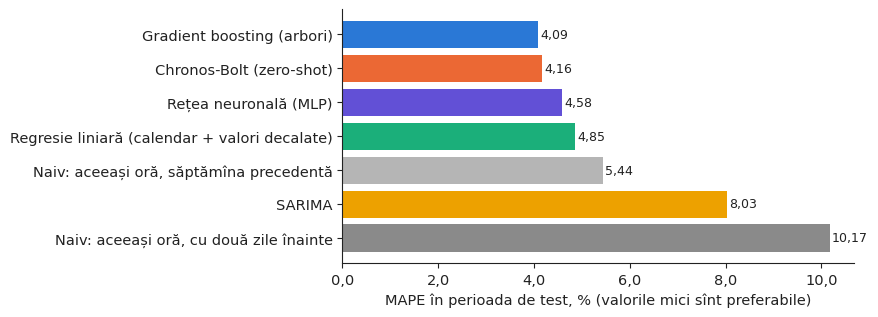

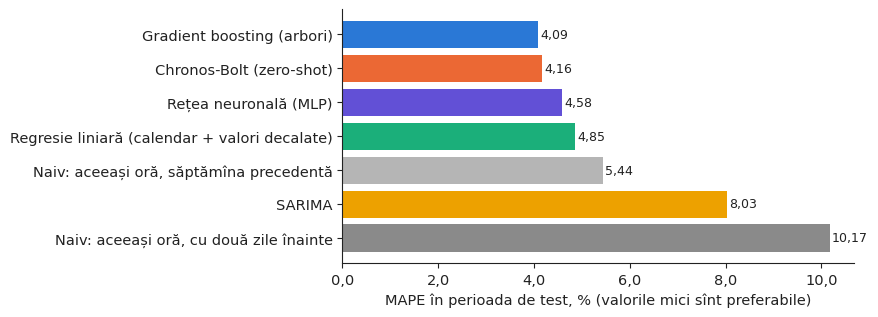

In [10]:
NAMES = {"Naive 48h": ("Naive: same hour two days earlier", "Naiv: aceeași oră, cu două zile înainte"), "Naive 168h": ("Naive: same hour last week", "Naiv: aceeași oră, săptămîna precedentă"),
         "Linear regression": ("Linear regression (calendar + lags)", "Regresie liniară (calendar + valori decalate)"),
         "Gradient boosting": ("Gradient boosting (trees)", "Gradient boosting (arbori)"), "Neural net (MLP)": ("Neural network (MLP)", "Rețea neuronală (MLP)"),
         "SARIMA": ("SARIMA", "SARIMA"), "Chronos-Bolt (zero-shot)": ("Chronos-Bolt (zero-shot)", "Chronos-Bolt (zero-shot)")}
tab = res.copy(); tab.index = [NAMES[i] for i in tab.index]
cu.write_table(tab, "accuracy", header=[("Model", "Model"), ("MAE, MW", "MAE, MW"), ("RMSE, MW", "RMSE, MW"), ("MAPE, \\%", "MAPE, \\%"), ("$R^2$", "$R^2$"), ("Bias, MW", "Abatere, MW")],
               digits={"MAE": 0, "RMSE": 0, "MAPE": 2, "R2": 3, "Bias": 0}, best={"MAE": "min", "RMSE": "min", "MAPE": "min", "R2": "max", "Bias": "absmin"})
COL = {"Naive 48h": cu.MUTED, "Naive 168h": "#b5b5b5", "Linear regression": cu.PAL["HU"], "SARIMA": cu.PAL["BG"],
       "Gradient boosting": cu.PAL["RO"], "Neural net (MLP)": cu.PAL["c7"], "Chronos-Bolt (zero-shot)": cu.PAL["DE_LU"]}
def fig_bar(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.3))
    r = res.sort_values("MAPE", ascending=False)
    ax.barh([cu.T(lang, *NAMES[i]) for i in r.index], r.MAPE, color=[COL[i] for i in r.index])
    for k, v in enumerate(r.MAPE):
        ax.text(v + 0.05, k, cu.fmt(v, 2, lang), va="center", fontsize=9)
    ax.set_xlabel(cu.T(lang, "MAPE on the test period, % (lower is better)", "MAPE în perioada de test, % (valorile mici sînt preferabile)"))
    cu.comma_axis(ax, lang, "x", 1)
    return fig
cu.save_both(fig_bar, "f2_mape_by_model", headline=True)

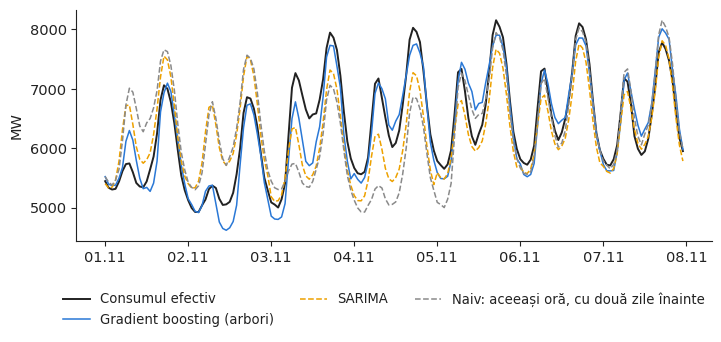

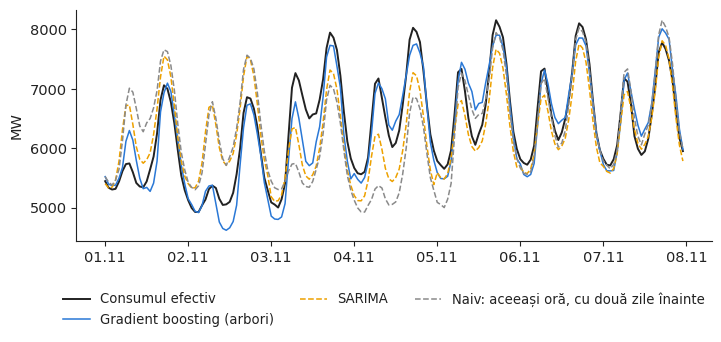

In [11]:
best = res.index[0]
k0 = [i for i, d in enumerate(days[:len(origins)]) if d.month == 11][:7]           # a week in November
wk_idx = np.concatenate([np.arange(origins[i], origins[i] + H) for i in k0])
def fig_week(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.0))
    t = idx[wk_idx]
    ax.plot(t, np.concatenate([actual[i] for i in k0]), color=cu.INK, lw=1.4, label=cu.T(lang, "Actual load", "Consumul efectiv"))
    for m_ in [best, "SARIMA", "Naive 48h"]:
        if m_ in fc:
            ax.plot(t, np.concatenate([fc[m_][i] for i in k0]), color=COL[m_], lw=1.1, ls="-" if m_ == best else "--", label=cu.T(lang, *NAMES[m_]))
    ax.set_ylabel("MW")
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_week, "f3_forecast_week")

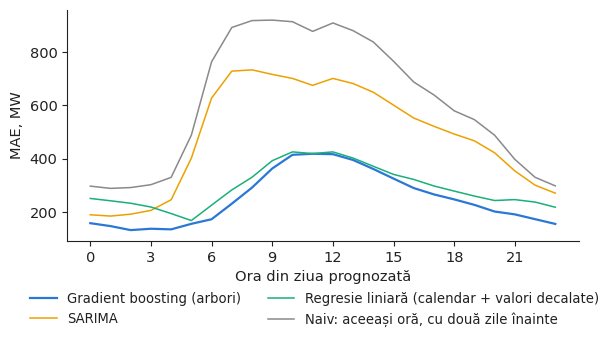

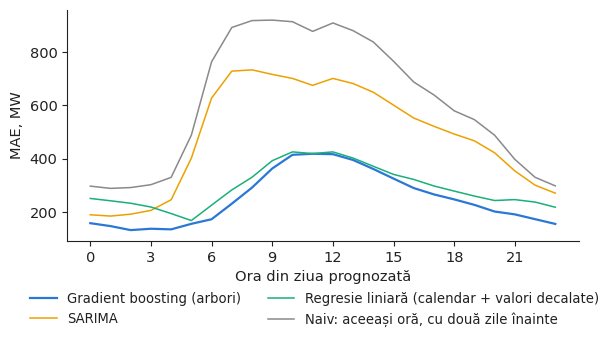

In [12]:
def fig_hour(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.0))
    for m_ in [best, "SARIMA", "Linear regression", "Naive 48h"]:
        mae_h = np.abs(actual - fc[m_]).mean(axis=0)
        ax.plot(range(24), mae_h, color=COL[m_], lw=1.6 if m_ == best else 1.1, label=cu.T(lang, *NAMES[m_]))
    ax.set_xlabel(cu.T(lang, "Hour of the forecast day", "Ora din ziua prognozată")); ax.set_ylabel(cu.T(lang, "MAE, MW", "MAE, MW"))
    ax.set_xticks(range(0, 24, 3))
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_hour, "f4_error_by_hour")

**Interpretarea rezultatului.** Consumul este o serie netedă, cu sezonalitate puternică: regula naivă săptămînală („aceeași oră, săptămîna precedentă”) greșește cu numai aproximativ 5 %,
în timp ce regula „aceeași oră, cu două zile înainte” este un reper slab, deoarece la închiderea porții ultima zi măsurată este d-2. Cele mai bune modele reduc MAPE (eroarea procentuală absolută medie)
cu aproximativ un punct procentual față de regula săptămînală, iar această îmbunătățire are valoare economică doar după ce este înmulțită cu volumul și cu costul dezechilibrelor.
Cel mai bun model din lucrare, N-BEATS, a obținut un MAPE de 2,324 %, față de 3,63 % pentru SARIMA (Tabelul 4, p. 157), cu un alt moment al prognozei
(următoarele 24 de ore după ultima oră observată), de aceea nivelurile nu sînt direct comparabile.

## 4. Decizia: cît valorează un punct procentual de MAPE?

In [13]:
# A supplier with a 10 % share of national consumption pays imbalances on its forecast error.
SHARE = 0.10           # market share (assumption for the exercise)
IMB = 50.0             # average cost of 1 MWh of imbalance, EUR/MWh (illustrative assumption: the gap between imbalance and day-ahead prices)
mae_naive = res.loc["Naive 48h", "MAE"]; mae_best = res.loc[best, "MAE"]
cost = lambda mae: mae * SHARE * 8760 * IMB / 1e6       # million EUR per year
print("best model:", best, "| MAE %.0f MW vs naive %.0f MW" % (mae_best, mae_naive))
print("annual imbalance cost, 10%% supplier: naive %.2f vs best %.2f million EUR -> saving %.2f million EUR" % (cost(mae_naive), cost(mae_best), cost(mae_naive) - cost(mae_best)))
cover = None
if chronos_q is not None:
    cover = 100 * ((actual >= chronos_q[:, :, 0]) & (actual <= chronos_q[:, :, 2])).mean()
    print("Chronos 80 %% interval coverage: %.1f %%" % cover)
cu.write_numbers({
    "nHours": len(load), "meanLoad": desc["mean"], "minLoad": desc["min"], "maxLoad": desc["max"], "sdLoad": desc["std"],
    "testStart": (f"{split:%d %B %Y}", f"{split:%d.%m.%Y}"), "nDays": len(origins),
    "bestName": NAMES[best], "bestMAPE": res.loc[best, "MAPE"], "bestMAE": mae_best, "bestRtwo": res.loc[best, "R2"],
    "naiveMAPE": res.loc["Naive 48h", "MAPE"], "naiveMAE": mae_naive, "weekMAPE": res.loc["Naive 168h", "MAPE"],
    "sarimaMAPE": res.loc["SARIMA", "MAPE"], "linMAPE": res.loc["Linear regression", "MAPE"], "gbmMAPE": res.loc["Gradient boosting", "MAPE"],
    "mlpMAPE": res.loc["Neural net (MLP)", "MAPE"],
    "chronosMAPE": res.loc["Chronos-Bolt (zero-shot)", "MAPE"] if "Chronos-Bolt (zero-shot)" in res.index else float("nan"),
    "cover": cover if cover is not None else float("nan"),
    "costNaive": cost(mae_naive), "costBest": cost(mae_best), "saving": cost(mae_naive) - cost(mae_best),
}, digits={"meanLoad": 2, "minLoad": 2, "maxLoad": 2, "sdLoad": 2, "bestMAE": 0, "naiveMAE": 0, "bestRtwo": 3, "cover": 1})

best model: Gradient boosting | MAE 250 MW vs naive 610 MW
annual imbalance cost, 10% supplier: naive 26.70 vs best 10.94 million EUR -> saving 15.76 million EUR
Chronos 80 % interval coverage: 85.1 %


In [14]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=1: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    other = [m_ for m_ in ["Chronos-Bolt (zero-shot)", "Gradient boosting", "SARIMA"] if m_ in res.index and m_ != best][:2]
    lines = [
        t("\\textbf{Forecasting national consumption} (Proșcanu, Proșcanu, Pele \\& Costea, 2025, RJEF): N-BEATS reaches MAPE 2.324\\,\\% vs 3.63\\,\\% for SARIMA on hourly load 2022--2024 (Table~4).",
          "\\textbf{Prognoza consumului național} (Proșcanu, Proșcanu, Pele și Costea, 2025, RJEF): pe consumul orar din 2022--2024, N-BEATS obține un MAPE de 2,324\\,\\%, față de 3,63\\,\\% pentru SARIMA (Tabelul~4)."),
        t(f"Our data reproduce the paper's series ({F(len(load), 0)} h, mean {F(desc['mean'], 1)} MW).",
          f"Datele cursului reproduc seria din lucrare ({F(len(load), 0)} de ore, media {F(desc['mean'], 1)} MW)."),
        t(f"Our replication ({len(origins)} test days from {split:%d %B %Y}): {NAMES[best][0]} MAPE {F(res.loc[best, 'MAPE'], 2)}\\,\\%, "
          + ", ".join(f"{NAMES[m_][0]} {F(res.loc[m_, 'MAPE'], 2)}\\,\\%" for m_ in other) + f", naive ``two days earlier'' {F(res.loc['Naive 48h', 'MAPE'], 2)}\\,\\%; forecasts issued at gate closure (load metered up to $d-2$).",
          f"Replicarea noastră ({len(origins)} de zile de test, din {split:%d.%m.%Y}): {NAMES[best][1]} are MAPE {F(res.loc[best, 'MAPE'], 2)}\\,\\%, "
          + ", ".join(f"{NAMES[m_][1]} {F(res.loc[m_, 'MAPE'], 2)}\\,\\%" for m_ in other) + f", iar regula naivă „acum două zile” {F(res.loc['Naive 48h', 'MAPE'], 2)}\\,\\%; prognozele sînt emise la închiderea porții (consum măsurat pînă în $d-2$)."),
        t(f"Decision: for a 10\\,\\% supplier, the best model cuts imbalance costs by $\\approx${F(cost(mae_naive) - cost(mae_best), 1)} mil.\\ EUR/year (at an illustrative 50 EUR/MWh).",
          f"Decizia: pentru un furnizor cu o cotă de 10\\,\\%, cel mai bun model reduce costul dezechilibrelor cu $\\approx${F(cost(mae_naive) - cost(mae_best), 1)} mil.\\ EUR/an (la un cost ilustrativ de 50 EUR/MWh)."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Forecasting national consumption} (Proșcanu, Proșcanu, Pele \& Costea, 2025, RJEF): N-BEATS reaches MAPE 2.324\,\% vs 3.63\,\% for SARIMA on hourly load 2022--2024 (Table~4).
  \item Our data reproduce the paper's series (26,304 h, mean 6,230.9 MW).
  \item Our replication (217 test days from 27 May 2024): Gradient boosting (trees) MAPE 4.09\,\%, Chronos-Bolt (zero-shot) 4.16\,\%, SARIMA 8.03\,\%, naive ``two days earlier'' 10.17\,\%; forecasts issued at gate closure (load metered up to $d-2$).
  \item Decision: for a 10\,\% supplier, the best model cuts imbalance costs by $\approx$15.8 mil.\ EUR/year (at an illustrative 50 EUR/MWh).
\end{itemize}



## Exerciții suplimentare
1. Împărțiți eșantionul 80/20 pe ore, ca în lucrare, și reestimați modelul SARIMA cu alte ordine și cu alte frecvențe de reestimare. Cum influențează aceste alegeri MAPE în perioada de test și timpul de calcul?
2. Adăugați temperatura (nu se află în dosarul de date al cursului, dar Open-Meteo oferă gratuit aceste date) în modelul gradient boosting. Pentru ce luni se îmbunătățește prognoza?
3. Folosiți intervalul 10 %–90 % al modelului Chronos ca plajă pentru volumul cumpărat la termen. Cît de des ați ieși în afara acestei plaje?